# 04 · Credit risk analysis: PD, calibration, thresholds and expected loss
Interprets the selected model (L2 logistic regression, chosen in notebook 03) from a financial-institution perspective.

**Test-set discipline.** Sections 1–5 use only training and validation data. The test set is first touched in section 6, **once**, for the selected model, with every choice (calibration, bands, threshold) already fixed. Rules fixed in advance:
- **Calibration:** a recalibrator (Platt sigmoid or isotonic) is adopted only if it lowers *out-of-fold* validation Brier score by more than 0.0003 versus raw probabilities; otherwise raw probabilities are used.
- **Risk bands (illustrative):** PD < 10%, 10–20%, 20–35%, 35–50%, ≥ 50%. These cut-offs are my own choice, not an institutional rating scale.
- **Threshold:** the threshold minimising validation misclassification cost when a missed defaulter (FN) is assumed to cost 5× a wrongly flagged good client (FP). The ratio is a hypothetical assumption, and a sensitivity range is shown.
- **Expected credit loss:** a clearly labelled *hypothetical* sensitivity analysis, since the dataset contains no LGD or EAD.

In [1]:
import sys, json; sys.path.insert(0, "..")
import numpy as np, pandas as pd, joblib, statsmodels.api as sm
from IPython.display import display
from sklearn.metrics import roc_auc_score
from src.data_loader import load_raw
from src.preprocessing import clean_categories, add_features, split_data, feature_columns, _signed_log, SEED
from src.train import coefficient_table
from src.evaluation import (evaluate, expected_calibration_error, calibrate_oof, Recalibrator,
                            threshold_sweep, hypothetical_ecl)
from src import visualisation as viz
viz.set_style(); pd.set_option("display.width", 200)
RESULTS = "../results"; MODELS = "../models"
df = add_features(clean_categories(load_raw()))
X_tr, X_va, X_te, y_tr, y_va, y_te = split_data(df)
SEL = json.load(open(f"{MODELS}/selection.json"))["selected_pd_model"]
models = {k: joblib.load(f"{MODELS}/logreg_{k}.joblib") for k in (SEL, "weighted")}
print("selected PD model:", SEL, "| test set is not used until section 6")

selected PD model: l2 | test set is not used until section 6


## 1. How the model produces a PD
For borrower *i* the model computes a linear score from the standardised features, $z_i = \beta_0 + \sum_j \beta_j x_{ij}$, and the probability of default is $\mathrm{PD}_i = 1/(1+e^{-z_i})$. Coefficients are log-odds changes per one standard deviation of a feature. **Horizon matters:** the target is default in the *next month*, so these are one-month PDs, not the 12-month PDs used for IFRS 9 stage 1 or Basel.

mean predicted PD 0.2183 | observed default rate 0.2212
PD percentiles (5/25/50/75/95/99): [0.079 0.104 0.136 0.273 0.629 0.818]


'results/figures/18_predicted_probability_distribution.png'

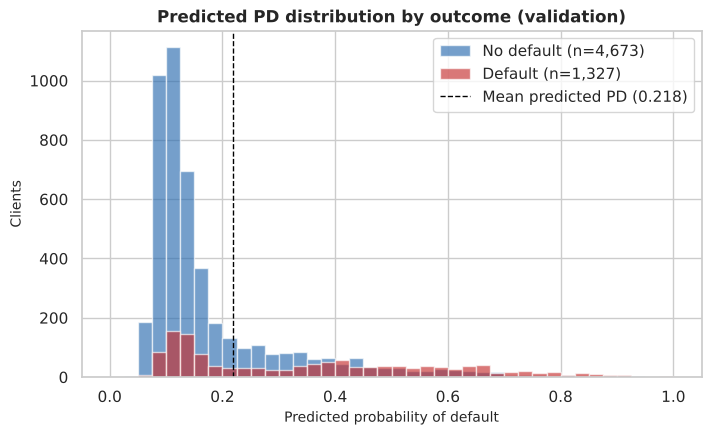

In [2]:
p_va_raw = models[SEL].predict_proba(X_va)[:, 1]
print(f"mean predicted PD {p_va_raw.mean():.4f} | observed default rate {y_va.mean():.4f}")
print("PD percentiles (5/25/50/75/95/99):", np.round(np.percentile(p_va_raw, [5, 25, 50, 75, 95, 99]), 3))
viz.plot_prob_distribution(y_va, p_va_raw)

**Interpretation.** The model's mean predicted PD (21.8%) is close to the observed validation default rate (22.1%). The distribution is strongly right-skewed: the median client has a PD of 13.6%, the 75th percentile 27%, the 95th percentile 63%. Most clients sit in a low-risk cluster of regular payers; a minority of delinquent clients carries high predicted PDs, and the defaulter and non-defaulter distributions overlap, consistent with an AUC of about 0.75 rather than a much higher value.

## 2. Probability calibration (validation data, out-of-fold)
Calibrators are evaluated out-of-fold on the validation set, so each point is recalibrated by a model that never saw it.

,mean_pred,brier,ece,roc_auc
L2 raw,0.2183,0.1434,0.0215,0.7501
L2 + sigmoid,0.2212,0.1434,0.0202,0.7501
L2 + isotonic,0.2216,0.1435,0.0117,0.7422
Weighted raw,0.4355,0.1915,0.2143,0.7552
Weighted + sigmoid,0.2212,0.1437,0.0186,0.7551
Weighted + isotonic,0.2212,0.1438,0.0109,0.7488


observed validation default rate: 0.2212


best recalibrator: L2 + sigmoid (Brier 0.1434) vs raw 0.1434 -> adopt recalibration: False


ROC-AUC(weighted) - ROC-AUC(L2), bootstrap mean 0.0050, 95% interval [0.0027, 0.0073]


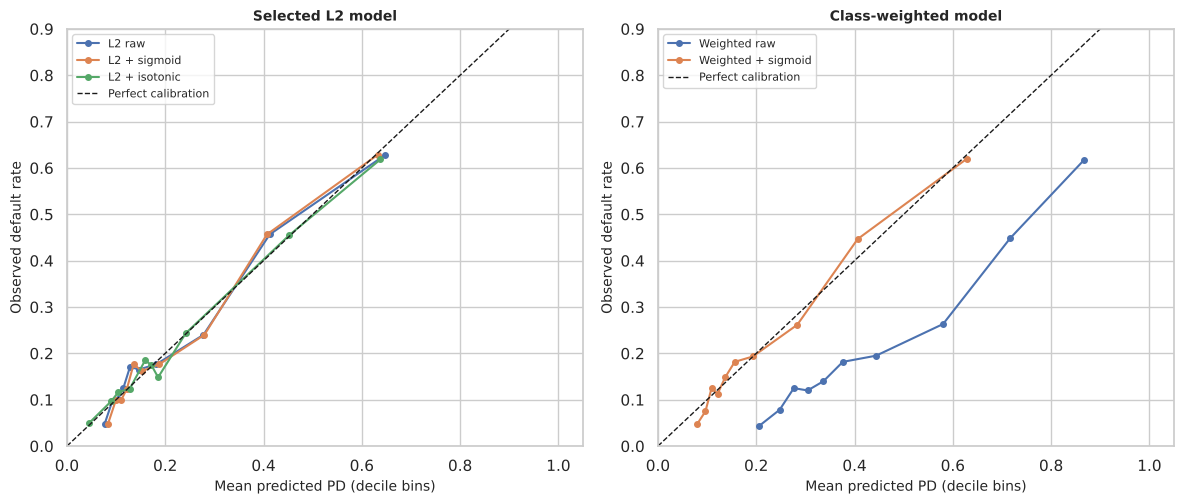

In [3]:
p_w_raw = models["weighted"].predict_proba(X_va)[:, 1]
variants = {"L2 raw": p_va_raw,
            "L2 + sigmoid": calibrate_oof(p_va_raw, y_va, "sigmoid", SEED),
            "L2 + isotonic": calibrate_oof(p_va_raw, y_va, "isotonic", SEED),
            "Weighted raw": p_w_raw,
            "Weighted + sigmoid": calibrate_oof(p_w_raw, y_va, "sigmoid", SEED),
            "Weighted + isotonic": calibrate_oof(p_w_raw, y_va, "isotonic", SEED)}
cal = pd.DataFrame({k: {"mean_pred": v.mean(), "brier": evaluate(y_va, v)["brier"], "ece": expected_calibration_error(y_va, v),
                        "roc_auc": roc_auc_score(y_va, v)} for k, v in variants.items()}).T
cal.round(4).to_csv(f"{RESULTS}/calibration_comparison.csv", index_label="variant")
display(cal.round(4)); print("observed validation default rate:", round(y_va.mean(), 4))
viz.plot_calibration({"Selected L2 model": {k: variants[k] for k in ("L2 raw", "L2 + sigmoid", "L2 + isotonic")},
                      "Class-weighted model": {k: variants[k] for k in ("Weighted raw", "Weighted + sigmoid")}}, y_va)

# pre-declared adoption rule
best_name, best_brier = min(((n, cal.loc[n, "brier"]) for n in ("L2 + sigmoid", "L2 + isotonic")), key=lambda t: t[1])
USE_CAL = best_brier < cal.loc["L2 raw", "brier"] - 0.0003
print(f"best recalibrator: {best_name} (Brier {best_brier:.4f}) vs raw {cal.loc['L2 raw', 'brier']:.4f} -> adopt recalibration: {USE_CAL}")
if USE_CAL:
    CAL = Recalibrator(best_name.split(" + ")[1]).fit(p_va_raw, y_va); to_pd = CAL.predict; p_pd_va = variants[best_name]
else:
    to_pd = lambda p: np.asarray(p); p_pd_va = p_va_raw

# paired bootstrap: is the class-weighted model's ranking advantage real? (validation only)
rng = np.random.default_rng(SEED); yv = y_va.to_numpy(); diffs = []
for _ in range(1000):
    i = rng.integers(0, len(yv), len(yv))
    diffs.append(roc_auc_score(yv[i], p_w_raw[i]) - roc_auc_score(yv[i], p_va_raw[i]))
print("ROC-AUC(weighted) - ROC-AUC(L2), bootstrap mean %.4f, 95%% interval [%.4f, %.4f]" % (np.mean(diffs), *np.percentile(diffs, [2.5, 97.5])))

**Interpretation.**
- **The selected L2 model is already well calibrated.** Mean predicted PD is 21.8% against 22.1% observed, and the reliability curve follows the diagonal. Out-of-fold recalibration does not improve the Brier score (0.1434 → 0.1434 sigmoid, 0.1435 isotonic). Isotonic lowers ECE (0.0215 → 0.0117) but costs ranking power (ROC-AUC 0.7501 → 0.7422) because it flattens scores into ties. Under the pre-declared rule (Brier must improve by > 0.0003) **no recalibration is adopted** and raw L2 probabilities are used. ECE values of this size are comparable to sampling noise in 600-client bins (a standard error of about 2 percentage points), so I do not read the small ECE differences as evidence either way.
- **Class weighting destroys calibration and recalibration repairs it.** The raw weighted model predicts a mean PD of 43.6% against 22.1% observed (Brier 0.1915, ECE 0.214). After Platt scaling its Brier score is 0.1437, essentially the same as L2, with ROC-AUC 0.7551.
- **This qualifies the model-selection result from notebook 03.** The paired bootstrap on validation gives a ROC-AUC advantage for the weighted model of 0.0050 (95% interval 0.0027 to 0.0073), so the ranking gain is unlikely to be pure validation noise. The interval only reflects resampling of the validation set, not training variability. I kept L2 as the selected model because that was the rule fixed in advance and because it needs no extra calibration step, but **a class-weighted model with sigmoid recalibration is a defensible alternative with slightly better discrimination.** I have not looked at it on the test set, to keep the test set single-use.

## 3. Borrower risk bands (illustrative)

,n,mean_predicted_pd,observed_default_rate,share_of_clients,share_of_defaults
<10%,1299,0.086,0.071,0.216,0.069
10-20%,2778,0.133,0.151,0.463,0.316
20-35%,764,0.270,0.236,0.127,0.136
35-50%,560,0.418,0.464,0.093,0.196
>=50%,599,0.648,0.628,0.100,0.283


'results/figures/19_risk_bands.png'

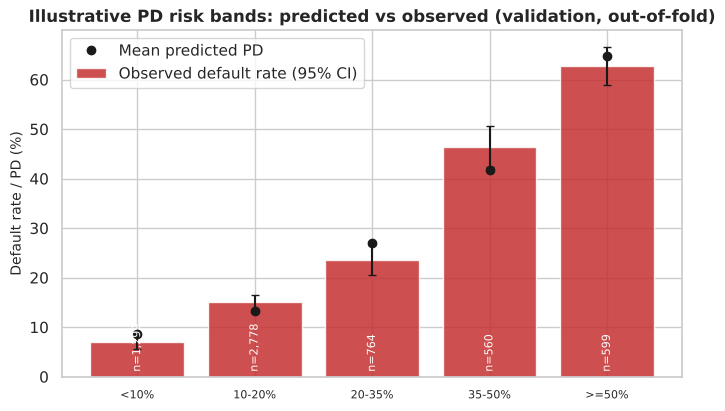

In [4]:
edges = [0, .10, .20, .35, .50, 1.0001]; labels = ["<10%", "10-20%", "20-35%", "35-50%", ">=50%"]
band = pd.cut(pd.Series(p_pd_va, index=X_va.index), edges, labels=labels, right=False)
bands = pd.DataFrame({"n": band.value_counts().reindex(labels),
                      "mean_predicted_pd": pd.Series(p_pd_va, index=X_va.index).groupby(band, observed=False).mean(),
                      "observed_default_rate": y_va.groupby(band, observed=False).mean()})
bands["share_of_clients"] = bands["n"] / bands["n"].sum()
bands["share_of_defaults"] = y_va.groupby(band, observed=False).sum() / y_va.sum()
bands.round(4).to_csv(f"{RESULTS}/risk_bands.csv", index_label="pd_band")
display(bands.round(3)); viz.plot_risk_bands(bands)

**Interpretation (bands are illustrative).** Predicted PD separates borrowers well: observed default rates rise from 7.1% in the lowest band to 62.8% in the highest. The 10% of clients with PD ≥ 50% account for 28% of all defaults, and the 22% of clients below 10% account for only 7%. Calibration within bands is reasonable but not perfect: the lowest band is over-predicted (8.6% predicted, 7.1% observed) and the 10–20% and 35–50% bands are under-predicted (13.3% vs 15.1%, 41.8% vs 46.4%). With 560–2,800 clients per band these gaps are within about two standard errors for most bands, so they are not strong evidence of miscalibration, but a bank would monitor them.

## 4. Coefficients, odds ratios, significance and multicollinearity
The significance tests come from an **unregularised** statsmodels `Logit` fitted on the same preprocessed training features. Coefficients and odds ratios are per +1 SD of a standardised feature. The L2 model's coefficients are shown beside them, since the L2 penalty shrinks them (and makes classical p-values inapplicable to the L2 fit itself).

converged: True | features: 31 | p < 0.05: 14


,coef,or,lo,hi,p,l2_coef,l2_or
n_late_months,0.552,1.737,1.591,1.896,0.000,0.476,1.610
PAY_0,0.327,1.386,1.306,1.471,0.000,0.312,1.366
max_delay,0.302,1.353,1.260,1.453,0.000,0.299,1.349
LIMIT_BAL,-0.175,0.839,0.797,0.883,0.000,-0.150,0.861
EDUCATION_4,-1.268,0.281,0.169,0.467,0.000,-0.213,0.808
MARRIAGE_2,-0.164,0.849,0.773,0.931,0.001,-0.134,0.874
BILL_AMT1,0.134,1.143,1.055,1.239,0.001,0.092,1.097
PAY_AMT3,-0.109,0.897,0.837,0.961,0.002,-0.095,0.909
PAY_2,-0.137,0.872,0.799,0.952,0.002,-0.077,0.925
PAY_AMT6,-0.074,0.928,0.882,0.977,0.004,-0.069,0.933


PAY_0: SD = 1.13; OR per +1 unit: unregularised 1.34, L2 1.32
max_delay: SD = 1.07; OR per +1 unit: unregularised 1.33, L2 1.32
n_late_months: SD = 1.56; OR per +1 unit: unregularised 1.43, L2 1.36
Approx. joint OR when a previously on-time client becomes one month late (PAY_0, max_delay, n_late_months each +1, other features fixed): 2.52
SD of signed-log LIMIT_BAL in training: 0.941
largest VIFs (engineered set): {'util_avg': 9.3, 'util_sep': 8.4, 'PAY_5': 7.1, 'PAY_4': 6.8}


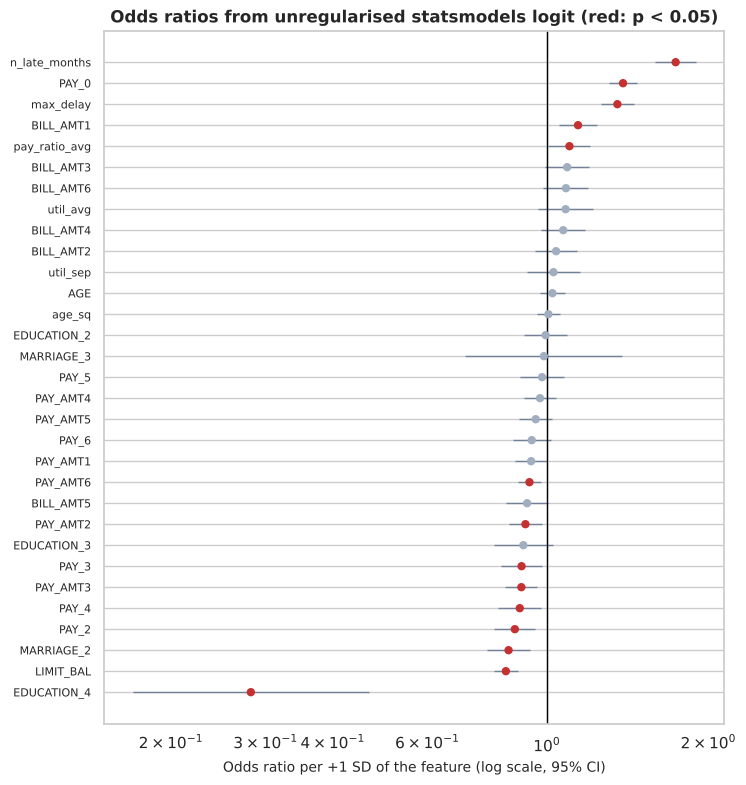

In [5]:
prep = models[SEL].named_steps["prep"]
Z_tr = prep.transform(X_tr)
logit = sm.Logit(y_tr, sm.add_constant(Z_tr)).fit(disp=0)
ci = logit.conf_int()
tab = pd.DataFrame({"coef": logit.params, "or": np.exp(logit.params), "lo": np.exp(ci[0]), "hi": np.exp(ci[1]), "p": logit.pvalues}).drop("const")
tab["l2_coef"] = coefficient_table(models[SEL])["coef"]; tab["l2_or"] = np.exp(tab["l2_coef"])
tab.round(4).to_csv(f"{RESULTS}/coefficients_odds_ratios.csv", index_label="feature")
print("converged:", logit.mle_retvals["converged"], "| features:", len(tab), "| p < 0.05:", int((tab["p"] < 0.05).sum()))
display(tab.sort_values("p").head(12).round(3))
viz.plot_odds_ratios(tab)

# odds ratios in natural units for delinquency variables (one more month / one more late month)
plain = feature_columns("engineered")[1]; sc = prep.named_transformers_["numeric"].scale_
for f in ("PAY_0", "max_delay", "n_late_months"):
    s = sc[plain.index(f)]
    print(f"{f}: SD = {s:.2f}; OR per +1 unit: unregularised {np.exp(tab.loc[f, 'coef'] / s):.2f}, L2 {np.exp(tab.loc[f, 'l2_coef'] / s):.2f}")
joint = sum(tab.loc[f, "coef"] / sc[plain.index(f)] for f in ("PAY_0", "max_delay", "n_late_months"))
print(f"Approx. joint OR when a previously on-time client becomes one month late (PAY_0, max_delay, n_late_months each +1, other features fixed): {np.exp(joint):.2f}")
print("SD of signed-log LIMIT_BAL in training:", round(float(_signed_log(X_tr['LIMIT_BAL']).std()), 3))
vif = pd.read_csv(f"{RESULTS}/vif_table.csv", index_col=0)
print("largest VIFs (engineered set):", vif["VIF_engineered"].sort_values(ascending=False).head(4).round(1).to_dict())

**Interpretation (association, not causation).**
- **Delinquency dominates.** `n_late_months`, `PAY_0` and `max_delay` have the largest odds ratios (1.74, 1.39 and 1.35 per +1 SD, all p < 0.001). They overlap mechanically (`max_delay` is at least `PAY_0`, and a late `PAY_0` also raises `n_late_months`), so they should be read together: a previously on-time client who falls one month behind moves all three, for a joint odds ratio of roughly 2.5 with other features held fixed (computed above). The credit-risk reading is simple: recent and repeated missed payments are by far the strongest warning signs.
- **Higher credit limits go with lower default risk** (OR 0.84 per +1 SD of log-limit, about a 2.6-fold higher limit). A limit reflects the issuer's own earlier assessment of the client, so this partly echoes the lender's information and should not be read as 'a bigger limit prevents default'.
- **Larger latest bills raise risk** (`BILL_AMT1` OR 1.14) and **larger repayments lower it** (`PAY_AMT3`, `PAY_AMT6`, `PAY_AMT2`: OR 0.90–0.93), as expected from a debt-burden perspective.
- **Single clients default less than married ones** (OR 0.85), a demographic association that I report but would treat cautiously in a real lending setting.
- **`EDUCATION_4` ('others') is unstable.** Its unregularised odds ratio is 0.28 (95% CI 0.17–0.47) but only 0.81 under L2 shrinkage. The group is small (about 280 training rows, with partly undocumented codes), so I would not interpret it substantively.
- **Coefficients of `PAY_2`–`PAY_6` are negative** (e.g. `PAY_2` OR 0.87), which looks contradictory but reflects adjustment for the correlated `PAY_0`, `max_delay` and `n_late_months`, not protective effects.
- **Significance and multicollinearity.** 14 of 31 features have p < 0.05, without any multiple-testing correction. The largest VIFs (9.3 for `util_avg`, 8.4 for `util_sep`) are below 10 but high enough that individual standard errors of correlated features are inflated, which is one reason the individual non-significant bill and utilisation terms should not be over-read. Predictive performance is not affected.

## 5. Classification thresholds (validation)

,rule,threshold,precision,recall,f1,flagged_share,fp,fn
0,0.50 (default),0.50,0.628,0.283,0.390,0.100,223,951
1,F1-optimal,0.32,0.523,0.513,0.518,0.217,621,646
2,KS / Youden,0.22,0.442,0.598,0.508,0.300,1003,533
3,"min cost, r=1",0.46,0.615,0.329,0.429,0.118,273,890
4,"min cost, r=2",0.34,0.540,0.493,0.515,0.202,557,673
5,"min cost, r=3.5",0.22,0.442,0.598,0.508,0.300,1003,533
6,"min cost, r=5",0.13,0.322,0.787,0.457,0.540,2194,283
7,"min cost, r=10",0.10,0.263,0.931,0.410,0.784,3466,92


theoretical cost-optimal threshold 1/(1+r): {1: 0.5, 2: 0.333, 3.5: 0.222, 5: 0.167, 10: 0.091}
chosen threshold T_STAR (cost ratio 5): 0.13


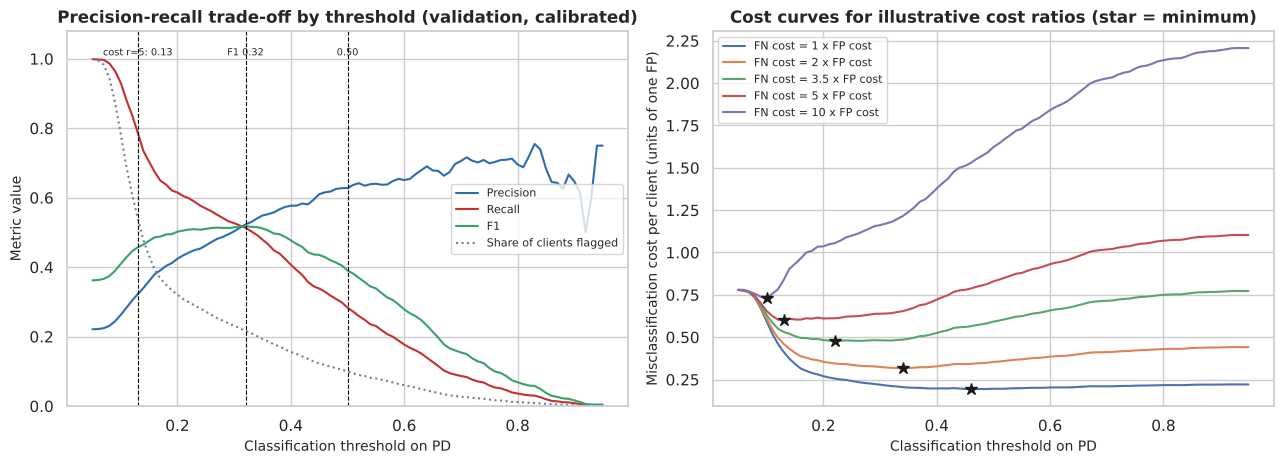

In [6]:
RATIOS = (1, 2, 3.5, 5, 10)
sweep = threshold_sweep(y_va, p_pd_va, cost_ratios=RATIOS)
sweep.round(5).to_csv(f"{RESULTS}/threshold_analysis.csv", index=False)
t_f1 = sweep.loc[sweep["f1"].idxmax(), "threshold"]
t_ks = sweep.loc[(sweep["tpr"] - sweep["fpr"]).idxmax(), "threshold"]
t_cost = {r: sweep.loc[sweep[f"cost_r{r}"].idxmin(), "threshold"] for r in RATIOS}
T_STAR = t_cost[5]
marks = {"0.50": 0.50, f"F1 {t_f1:.2f}": t_f1, f"cost r=5: {T_STAR:.2f}": T_STAR}
viz.plot_threshold_analysis(sweep, marks, RATIOS)
pick = {"0.50 (default)": 0.50, f"F1-optimal": t_f1, "KS / Youden": t_ks, **{f"min cost, r={r}": t for r, t in t_cost.items()}}
rows = []
for k, t in pick.items():
    r = sweep.loc[(sweep["threshold"] - t).abs().idxmin()]
    rows.append({"rule": k, "threshold": t, "precision": r.precision, "recall": r.recall, "f1": r.f1, "flagged_share": r.flagged_share, "fp": int(r.fp), "fn": int(r.fn)})
display(pd.DataFrame(rows).round(3))
print("theoretical cost-optimal threshold 1/(1+r):", {r: round(1 / (1 + r), 3) for r in RATIOS})
print("chosen threshold T_STAR (cost ratio 5):", T_STAR)

**Interpretation.**
- **0.50 is not a sensible threshold here.** At 0.50 the model flags 10% of clients, with precision 63% but recall only 28%, so it misses 951 of 1,327 validation defaulters.
- **Lowering the threshold trades false negatives for false positives.** The F1-optimal threshold (0.32) balances precision 52% and recall 51%. At 0.22 (the KS/Youden point) recall is 60% with precision 44% and 30% of clients flagged.
- **The right threshold depends on the cost ratio, which is a business input.** If a missed defaulter costs about 2× a wrongly refused good client, the cost-minimising threshold is 0.34, at 3.5× it is 0.22, at 5× it is 0.13 and at 10× it is 0.10. For a calibrated model theory gives 1/(1+r): 0.33, 0.22, 0.17 and 0.09, which the empirical thresholds roughly track (0.13 against 0.167 at r = 5, because the cost curve is very flat there).
- **The pre-declared choice (r = 5, threshold 0.13) is aggressive.** It flags 54% of clients to catch 79% of defaulters, with precision of only 32% and 2,194 false positives against 283 false negatives. It would suit a decision where a missed default is very costly relative to a declined or monitored good client (for example flagging accounts for review rather than declining them), not automatic rejection. The ratio of 5 is hypothetical; a real institution would derive it from LGD, EAD, margin and the cost of the action taken.

## 6. Final test-set evaluation (first and only use of the test set)
Selected L2 model, raw probabilities as decided in section 2, threshold fixed in section 5. Nothing below feeds back into any choice.

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier,ks,tn,fp,fn,tp
validation @0.50,0.8043,0.6277,0.2833,0.3904,0.7501,0.4926,0.1434,0.3850,4450.0,223.0,951.0,376.0
test @0.50,0.8110,0.6633,0.2954,0.4088,0.7649,0.5198,0.1389,0.4243,4474.0,199.0,935.0,392.0
validation @0.13,0.5872,0.3224,0.7867,0.4574,0.7501,0.4926,0.1434,0.3850,2479.0,2194.0,283.0,1044.0
test @0.13,0.5970,0.3296,0.7950,0.4660,0.7649,0.5198,0.1389,0.4243,2527.0,2146.0,272.0,1055.0


test default rate 0.2212 | mean predicted PD 0.2206 | ECE 0.0224


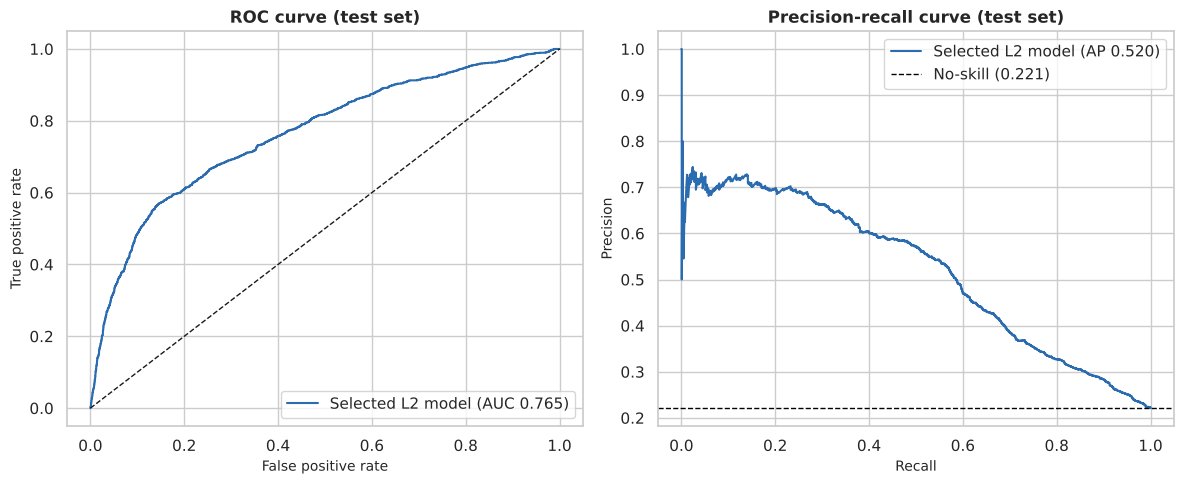

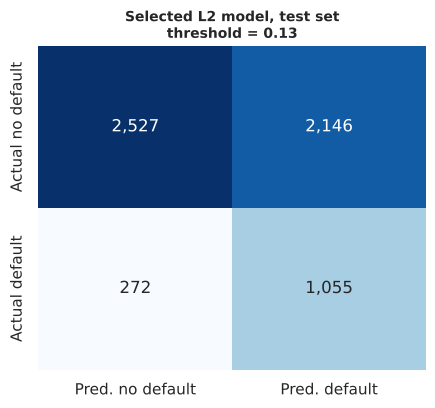

In [7]:
p_te = to_pd(models[SEL].predict_proba(X_te)[:, 1])
res = {"validation @0.50": evaluate(y_va, p_pd_va, 0.5), "test @0.50": evaluate(y_te, p_te, 0.5),
       f"validation @{T_STAR:.2f}": evaluate(y_va, p_pd_va, T_STAR), f"test @{T_STAR:.2f}": evaluate(y_te, p_te, T_STAR)}
final = pd.DataFrame(res).T
display(final[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "brier", "ks", "tn", "fp", "fn", "tp"]].astype(float).round(4))
final.round(5).to_csv(f"{RESULTS}/final_test_summary.csv", index_label="evaluation")
print("test default rate %.4f | mean predicted PD %.4f | ECE %.4f" % (y_te.mean(), p_te.mean(), expected_calibration_error(y_te, p_te)))
viz.plot_scores_roc_pr(y_te, p_te, "Selected L2 model", "test set")
viz.plot_confusion_one(y_te, p_te, T_STAR, "Selected L2 model, test set")

# append the test rows to model_metrics.csv (rebuilt so reruns do not duplicate)
mm = pd.read_csv(f"{RESULTS}/model_metrics.csv"); mm = mm[mm["split"] != "test"]
mm = pd.concat([mm, pd.DataFrame([{"model": SEL, "split": "test", **evaluate(y_te, p_te, 0.5)}])], ignore_index=True)
mm.round(5).to_csv(f"{RESULTS}/model_metrics.csv", index=False)

**Interpretation.**
- **Test performance is consistent with, and slightly better than, validation.** ROC-AUC is about 0.765 on test against 0.7501 on validation (and 0.7650 in training cross-validation); PR-AUC 0.520 against 0.493; KS 0.424 against 0.385. A difference of about 0.015 is within sampling noise for 6,000-row sets, so I read this as validation being slightly harder than test and not as evidence that the test set was used for tuning (it was not). The validation numbers are the more conservative estimate.
- **Calibration holds out of sample.** Mean predicted PD is 22.06% against an observed 22.12%, and ECE is 0.022, similar to validation. The Brier score is 0.1389 versus the 0.1434 validation score.
- **At the pre-declared threshold (0.13)** the test results mirror validation: recall 79.5%, precision 33.0%, with 2,146 false positives and 272 false negatives.
- Test metrics at 0.50 are saved in `results/model_metrics.csv` and the other evaluation rows in `results/final_test_summary.csv`.

## 7. Expected credit loss: a hypothetical sensitivity analysis
$$\mathrm{ECL} = \mathrm{PD} \times \mathrm{LGD} \times \mathrm{EAD}$$
- **PD:** the model's one-month probability of default (estimated from the data).
- **LGD** (share of the exposure lost if default occurs) and **EAD** (exposure at default) are **not in the dataset**: there are no recoveries, collateral or post-default balances.

So the figures below are **not an estimate of this bank's actual expected loss.** They show how ECL responds to *assumed* LGD and EAD. EAD is assumed to be the latest bill plus a credit conversion factor (CCF) times the undrawn limit; LGD values of 25–75% are assumed (45% is the Basel foundation-IRB figure for senior unsecured exposures, and unsecured card loans can run higher). Computed on the test set's calibrated PDs.

total credit limit, test set: NT$ 1012 m | total latest bill (drawn): NT$ 301 m
HYPOTHETICAL ECL, NT$ million (rows LGD, columns CCF)


,0.0,0.5,1.0
0.25,15.7,29.8,43.9
0.45,28.3,53.6,79.0
0.60,37.8,71.5,105.3
0.75,47.2,89.4,131.6


HYPOTHETICAL ECL as % of total credit limit


,0.0,0.5,1.0
0.25,1.56,2.95,4.34
0.45,2.80,5.30,7.80
0.60,3.73,7.07,10.41
0.75,4.67,8.84,13.01


,share_of_clients,share_of_ECL
<10%,0.221,0.162
10-20%,0.447,0.281
20-35%,0.130,0.162
35-50%,0.103,0.180
>=50%,0.098,0.214


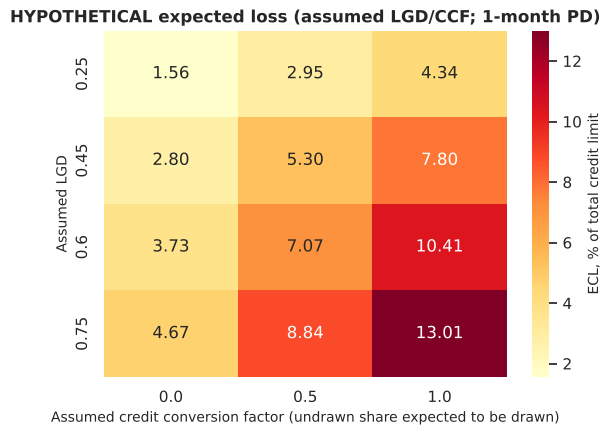

In [8]:
lgds, ccfs = [0.25, 0.45, 0.60, 0.75], [0.0, 0.5, 1.0]
grid = pd.DataFrame(index=lgds, columns=ccfs, dtype=float); grid_abs = grid.copy()
for l in lgds:
    for c in ccfs:
        ecl, ead = hypothetical_ecl(p_te, X_te["BILL_AMT1"], X_te["LIMIT_BAL"], l, c)
        grid.loc[l, c] = ecl.sum() / X_te["LIMIT_BAL"].sum(); grid_abs.loc[l, c] = ecl.sum() / 1e6
grid.round(5).to_csv(f"{RESULTS}/hypothetical_ecl_sensitivity.csv", index_label="lgd")
print("total credit limit, test set: NT$ %.0f m | total latest bill (drawn): NT$ %.0f m" % (X_te["LIMIT_BAL"].sum() / 1e6, X_te["BILL_AMT1"].clip(lower=0).sum() / 1e6))
print("HYPOTHETICAL ECL, NT$ million (rows LGD, columns CCF)"); display(grid_abs.round(1))
print("HYPOTHETICAL ECL as % of total credit limit"); display((grid * 100).round(2))
viz.plot_ecl_heatmap(grid)

# where the hypothetical loss concentrates (LGD 45%, CCF 50%)
ecl, ead = hypothetical_ecl(p_te, X_te["BILL_AMT1"], X_te["LIMIT_BAL"], 0.45, 0.5)
tb = pd.cut(pd.Series(p_te, index=X_te.index), edges, labels=labels, right=False)
conc = pd.DataFrame({"share_of_clients": tb.value_counts(normalize=True).reindex(labels),
                     "share_of_ECL": pd.Series(ecl, index=X_te.index).groupby(tb, observed=False).sum() / ecl.sum()})
display(conc.round(3))

**Interpretation (hypothetical, not a measurement of real loss).**
- Across the assumed ranges the hypothetical ECL runs from **1.6% to 13.0% of the total credit limit**, a factor-of-eight spread, and it is driven almost entirely by the *assumptions* (LGD 25–75% and CCF 0–100%), not by the model. For example, at LGD 45% and CCF 50% it is about NT$ 54 m on a NT$ 1.0 bn limit (5.3%), and at LGD 45% with no undrawn drawdown it is NT$ 28 m, about 9% of the NT$ 301 m currently drawn.
- **What the model does contribute is the ranking of where loss sits.** Clients with PD ≥ 50% are 9.8% of the test portfolio but 21% of hypothetical ECL, and the two bands below 20% are 67% of clients but 44% of ECL. Even low-PD clients contribute substantially because they are numerous and carry large limits.
- **Why these figures cannot be used as actual ECL.** (1) LGD and EAD are assumed. (2) The PD is a one-month PD, not a 12-month or lifetime PD, and cannot be annualised by simple multiplication. (3) The 22% default rate comes from a Taiwanese card portfolio in 2005, during a well-documented consumer-credit stress, and is far above typical card default rates today. (4) The ECL here is an unweighted sum on a 6,000-client test sample, without discounting, macro scenarios or staging as IFRS 9 would require.